In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open("names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [5]:
#Building the dataset

block_size = 3 #context length: how many characters do we take to predict the next one
X, Y = [], []
for w in words[:3]:
    print(w)
    context = [0] * block_size
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print("".join(itos[i] for i in context), "--->", itos[ix])
        context = context[1:] + [ix]
X = torch.tensor(X)
Y = torch.tensor(Y)

emma
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
... ---> a
..a ---> v
.av ---> a
ava ---> .


In [6]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([16, 3]), torch.int64, torch.Size([16]), torch.int64)

In [7]:
X


tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        [ 5, 13, 13],
        [13, 13,  1],
        [ 0,  0,  0],
        [ 0,  0, 15],
        [ 0, 15, 12],
        [15, 12,  9],
        [12,  9, 22],
        [ 9, 22,  9],
        [22,  9,  1],
        [ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 22],
        [ 1, 22,  1]])

In [8]:
Y

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0])

In [9]:
C = torch.randn((27,2))

In [10]:
C[5]

tensor([-0.2504,  0.1921])

In [11]:
F.one_hot((torch.tensor(5)), num_classes=27).float() @ C

tensor([-0.2504,  0.1921])

In [12]:
emb = C[X]
emb.shape

torch.Size([16, 3, 2])

In [13]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [14]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

torch.Size([16, 6])

In [15]:
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1)

tensor([[-0.2100,  0.7178, -0.2100,  0.7178, -0.2100,  0.7178],
        [-0.2100,  0.7178, -0.2100,  0.7178, -0.2504,  0.1921],
        [-0.2100,  0.7178, -0.2504,  0.1921, -0.8886,  0.8815],
        [-0.2504,  0.1921, -0.8886,  0.8815, -0.8886,  0.8815],
        [-0.8886,  0.8815, -0.8886,  0.8815,  1.0636,  0.6122],
        [-0.2100,  0.7178, -0.2100,  0.7178, -0.2100,  0.7178],
        [-0.2100,  0.7178, -0.2100,  0.7178,  0.5450,  2.4441],
        [-0.2100,  0.7178,  0.5450,  2.4441, -0.7264,  0.7698],
        [ 0.5450,  2.4441, -0.7264,  0.7698, -1.4937,  0.1908],
        [-0.7264,  0.7698, -1.4937,  0.1908, -0.3580,  1.0408],
        [-1.4937,  0.1908, -0.3580,  1.0408, -1.4937,  0.1908],
        [-0.3580,  1.0408, -1.4937,  0.1908,  1.0636,  0.6122],
        [-0.2100,  0.7178, -0.2100,  0.7178, -0.2100,  0.7178],
        [-0.2100,  0.7178, -0.2100,  0.7178,  1.0636,  0.6122],
        [-0.2100,  0.7178,  1.0636,  0.6122, -0.3580,  1.0408],
        [ 1.0636,  0.6122, -0.3580,  1.0

In [16]:
torch.cat(torch.unbind(emb, 1), 1).shape

torch.Size([16, 6])

In [17]:
a = torch.arange(18)
a

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17])

In [18]:
a.view(2,3,3)

tensor([[[ 0,  1,  2],
         [ 3,  4,  5],
         [ 6,  7,  8]],

        [[ 9, 10, 11],
         [12, 13, 14],
         [15, 16, 17]]])

In [19]:
h = torch.tanh(emb.view(-1, 6) @W1+b1)

In [20]:
h

tensor([[-0.0653, -0.7682,  0.9520,  ...,  0.4928, -0.3545,  0.2796],
        [ 0.0841, -0.1707,  0.9329,  ..., -0.3380, -0.7155,  0.6960],
        [ 0.1082, -0.3377,  0.9632,  ..., -0.5740, -0.9531,  0.8171],
        ...,
        [-0.9094, -0.8466,  0.9317,  ...,  0.9979,  0.9372, -0.5703],
        [-0.1677, -0.9996, -0.5343,  ...,  0.9669, -0.9668, -0.2078],
        [ 0.0267, -0.9768, -0.9231,  ...,  0.9992,  0.9997,  0.5275]])

In [21]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [22]:
logits = h @ W2 + b2

In [23]:
logits.shape

torch.Size([16, 27])

In [24]:
counts = logits.exp()
prob = counts/counts.sum(1, keepdims = True)
prob.shape

torch.Size([16, 27])

In [25]:
#Summarizing eveyrthing above in short=

X.shape, Y.shape  # dataset

(torch.Size([16, 3]), torch.Size([16]))

In [26]:
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((27, 2), generator=g, requires_grad=True)
W1 = torch.randn((6, 300), generator=g, requires_grad=True)
b1 = torch.randn(300, generator=g, requires_grad=True)
W2 = torch.randn((300, 27), generator=g, requires_grad=True)
b2 = torch.randn(27, generator=g, requires_grad=True)

parameters = [C, W1, b1, W2, b2]

In [27]:
sum(p.nelement() for p in parameters)  # number of parameters in total

10281

In [28]:
for p in parameters:
  p.requires_grad = True

In [29]:
logits = torch.tensor([-5,-3,0,5])
counts = logits.exp()
probs = counts/counts.sum()
probs

tensor([4.5079e-05, 3.3309e-04, 6.6903e-03, 9.9293e-01])

In [30]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [31]:
print("C:", C.shape)
print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

C: torch.Size([27, 2])
W1: torch.Size([6, 300])
b1: torch.Size([300])
W2: torch.Size([300, 27])
b2: torch.Size([27])


In [32]:
lri = []
lossi = []

for i in range(1000):

    # Minibatch construct
    ix = torch.randint(0, X.shape[0], (32,))

    # Forward pass
    emb = C[X[ix]]                     # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 300)
    logits = h @ W2 + b2              # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])

    # Backward pass
    for p in parameters:
        p.grad = None

    loss.backward()

    # Update parameters
    lr = 0.01
    with torch.no_grad():
        for p in parameters:
            p -= lr * p.grad

    # Store learning rate and loss
    lri.append(lr)
    lossi.append(loss.item())

print("Final loss:", loss.item())

Final loss: 0.18023954331874847


Final minibatch loss: 0.17548179626464844


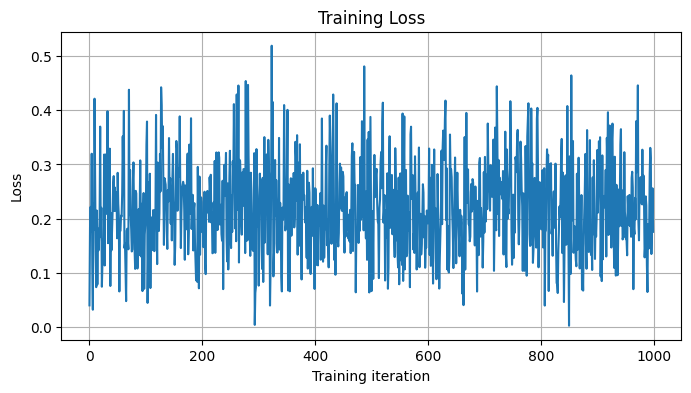

In [33]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

lri = []
lossi = []

for i in range(1000):

    # Minibatch
    ix = torch.randint(0, X.shape[0], (32,))

    # Forward pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    # Backward pass
    for p in parameters:
        p.grad = None

    loss.backward()

    # Update parameters
    lr = 0.01

    with torch.no_grad():
        for p in parameters:
            p -= lr * p.grad

    lri.append(lr)
    lossi.append(loss.item())

print("Final minibatch loss:", loss.item())

plt.figure(figsize=(8, 4))
plt.plot(lossi)
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

In [34]:
torch.randint(0, X.shape[0],(32,))

tensor([ 6, 10, 14,  8, 11,  1,  7,  9, 15,  6, 10,  0,  4,  2,  5,  0,  1,  5,
        14,  9,  1,  7,  3,  8,  0,  6, 15,  8,  1, 15,  3, 10])

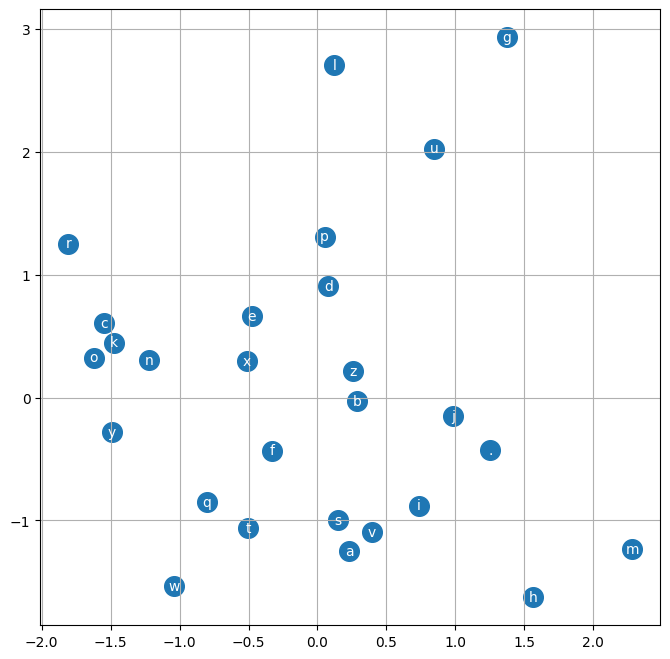

In [35]:
plt.figure(figsize = (8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
  plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va = "center", color = "white")
plt.grid("minor")

In [36]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(3):

    out = []
    context = [0] * block_size  # initialize with all ...

    while True:
        emb = C[torch.tensor([context])]  # (1, block_size, d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()

        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:
            break

    print(''.join(itos[i] for i in out))

olivia.
ava.
olivia.
